# The mock observation, step by step, by hand

`scripts/gen_mock_data.py` makes `data/` by calling the falcon nodes of `src/model.py`, which call
`src/functionlistnew.py`. This notebook does **the same computation without importing either module**:
every step is written out here with plain `torch` / `numpy`, starting from the stored truth
(`data/true_z.npy`, `data/true_pw.npy`) and the raw UV-track file. After each step the result is
compared with the corresponding file in `data/`.

The chain we rebuild (node names of `config.yml`):

```
z ──► gains ──► baseline gain products ──► stacked_uv (gain-weighted UV coverage) ─┐
                     │                                                             ├─► tracked_uv ─► normed ─► x ─► obsx ─► pk_obs
pw ──► δ (df) ──► T_b (bt) ──► image ──► uvimage (FFT of the sky) ─────────────────┘
                     └──────────────────────────────► V_ref = g_i S_ref[i,j] g_j*    (calibrator, dense path)
```

**What "the same result" means here.** Every array is compared with the stored one and reported as
`max |mine − data|`. Because we redo the identical float32 operations on the same device (the truth
was drawn on the CPU, see `data/mock_device.npy`), we expect — and get — **bit-identical** results, not
just agreement to rounding. A summary table is at the end.

No project code is imported. The set-up constants (grid, box, seeds, …) are typed in below
and then *checked* against `src/settings.py`, so the notebook is self-contained but cannot silently drift.

In [1]:
import sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm

# project root = first parent folder holding config.yml (works from tests/ or from the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yml").exists())
DATA = ROOT / "data"

# The truth was drawn on this device; torch's seeded RNG differs between CPU and GPU,
# so to reproduce the seeded density field we must run on the same one.
MOCK_DEVICE = str(np.load(DATA / "mock_device.npy"))
DEV = torch.device(MOCK_DEVICE if (MOCK_DEVICE == "cpu" or torch.cuda.is_available()) else "cpu")
print("root:", ROOT, "| data made on:", MOCK_DEVICE, "| running on:", DEV)

# ---- plotting style (one categorical order: data = blue, mine = orange, third = aqua)
C_DATA, C_MINE, C_3 = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "lines.linewidth": 2, "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "image.origin": "upper",
})

def show(ax, img, title, cmap="Blues", norm=None, extent=None, cbar=True):
    im = ax.imshow(img, cmap=cmap, norm=norm, extent=extent, interpolation="nearest")
    ax.set_title(title); ax.grid(False)
    if cbar:
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    return im

# ---- the comparison log used throughout
checks = []
def compare(name, mine, ref):
    mine = np.asarray(mine.detach().cpu() if torch.is_tensor(mine) else mine)
    ref = np.asarray(ref)
    assert mine.shape == ref.shape, f"{name}: shape {mine.shape} vs {ref.shape}"
    same_nan = np.array_equal(np.isnan(mine), np.isnan(ref))
    m, r = np.nan_to_num(mine), np.nan_to_num(ref)
    diff, scale = np.abs(m - r).max(), np.abs(r).max()
    exact = bool(np.array_equal(m, r) and same_nan)
    checks.append((name, mine.shape, diff, scale, exact))
    print(f"{name:22s} max|mine − data| = {diff:.3e}   (max|data| = {scale:.3e})   "
          f"{'BIT-IDENTICAL' if exact else 'differs'}")

root: /gpfs/home3/jsanghavi1/Pictures/jointstrategy/paperfinalaastar | data made on: cpu | running on: cpu


## 0. Load what `gen_mock_data.py` wrote

`pk_obs` and `V_ref_obs` are what falcon actually conditions on (`observed:` in `config.yml`); the
rest are intermediate products and the truth.

In [2]:
D = {f.stem: np.load(f) for f in sorted(DATA.glob("*.npy"))}
for k, v in D.items():
    print(f"{k:18s} {str(v.shape):14s} {v.dtype}")
print("\ntrue pw =", D["true_pw"][0], "  (log10 A, n1, n2, log10 k_break)")

S_obs              (307, 307)     complex64
S_ref              (307, 307)     complex64
V_dense_obs        (307, 307)     complex64
V_ref_obs          (307, 307)     complex64
image              (128, 128)     float32
mock_device        ()             <U3
obsx_obs           (2, 128, 128)  float32
pk_obs             (2, 50)        float32
true_delta         (1, 128, 128)  float32
true_k             (50,)          float32
true_pk_measured   (50,)          float32
true_pw            (1, 4)         float64
true_z             (1, 212)       float32
x_obs              (2, 128, 128)  complex64

true pw = [-1.8 -2.  -3.  -0.3]   (log10 A, n1, n2, log10 k_break)


## 1. Set-up constants (typed in, then checked against `src/settings.py`)

In [3]:
N_PIX, BOX = 128, 512.0                    # grid side [px], box side [Mpc]
DX = BOX / N_PIX                           # 4 Mpc per pixel
REDSHIFT = 9.0
N_SUBSETS = 2                              # baselines split into 2 UV maps
KNOWN_ANT = 200                            # stations with known g = 1
NOISE_STD = 0.0                            # thermal noise switched off
CAL_FLUX, CAL_SIGMA = 2.7, 0.3             # calibrator peak [mK], width [px]
FOREGROUND = 0.0                           # science foreground flux [mK]
Z_SEED, Z_SCALE, FIELD_SEED = 99, 0.3, 54
N_BINS = 50                                # k-bins of the P(k) estimator
H_LITTLE, OM_M, OM_B, Y_P = 0.674, 0.315, 0.0492, 0.2454   # Planck 2018

# cross-check against the project's single source of truth (pure-constants module)
sys.path.insert(0, str(ROOT / "src")); import settings
assert (N_PIX, BOX, REDSHIFT, N_SUBSETS, KNOWN_ANT, NOISE_STD, CAL_FLUX, CAL_SIGMA, FOREGROUND,
        Z_SEED, Z_SCALE, FIELD_SEED) == (settings.N_PIX, settings.BOX_SIZE, settings.REDSHIFT,
        settings.N_SUBSETS, settings.KNOWN_ANT, settings.NOISE_STD, settings.CALIBRATOR_FLUX,
        settings.CALIBRATOR_SIGMA, settings.SCIENCE_FOREGROUND_FLUX, settings.TRUE_Z_SEED,
        settings.TRUE_Z_SCALE, settings.TRUE_FIELD_SEED)
assert (H_LITTLE, OM_M, OM_B, Y_P) == (settings.HUBBLE_H, settings.OMEGA_M, settings.OMEGA_B, settings.HELIUM_Y)
assert tuple(D["true_pw"][0]) == settings.TRUE_PW
print("constants agree with settings.py; pixel =", DX, "Mpc")

constants agree with settings.py; pixel = 4.0 Mpc


## 2. The instrument: baseline tracks and station layout

`paddedAAstar_4_30_9_128_512.pth` holds, for every baseline (station pair *i < j*), its track over
the 4 h observation already gridded onto the 128×128 UV grid: shape `(K, 3, L)` with rows
`x` (UV column), `y` (UV row) and `t` (how many 30 s integrations fell into that pixel). Tracks are
padded with zeros to the longest one (`L = 52` pixels). Pixel indices are in **FFT order**
(DC at `[0, 0]`, negative frequencies wrapped to the end).

The number of stations follows from `K = N(N−1)/2`.

In [4]:
padded = torch.load(ROOT / "src/paddedAAstar_4_30_9_128_512.pth", map_location=DEV, weights_only=True)
K, _, L = padded.shape
NANT = int(round((1 + np.sqrt(1 + 8 * K)) / 2))
assert NANT * (NANT - 1) // 2 == K
N_UNK = NANT - 1 - KNOWN_ANT
print(f"{K} baselines, track length {L} → {NANT} stations: 1 reference + {N_UNK} unknown + {KNOWN_ANT} known")

t_all = padded[:, 2, :]
n_per_bl = t_all.sum(-1)                         # integrations per baseline (0 if never on the grid)
observed_bl = n_per_bl > 0
print(f"baselines that land on the grid: {observed_bl.sum().item()},  never: {(~observed_bl).sum().item()}")
print(f"a full 4 h track is {4*3600/30:.0f} integrations; max per baseline on the grid = {n_per_bl.max().item():.0f}")

# baseline (i, j) ordering = torch.triu_indices, the order of the tracks file
I, J = torch.triu_indices(NANT, NANT, offset=1, device=DEV)
print("first baselines:", list(zip(I[:3].tolist(), J[:3].tolist())), "... last:", (I[-1].item(), J[-1].item()))

46971 baselines, track length 52 → 307 stations: 1 reference + 106 unknown + 200 known
baselines that land on the grid: 26725,  never: 20246
a full 4 h track is 480 integrations; max per baseline on the grid = 480
first baselines: [(0, 1), (0, 2), (0, 3)] ... last: (305, 306)


Why do ~20 000 baselines never reach the grid? The grid's UV cell is set by the box (512 Mpc ≈ the
field of view), and the highest UV frequency it holds (Nyquist, 64 cells) corresponds to a physical
baseline of roughly 2.5 km at z = 9. Longer baselines fall outside. The layout file lets us check
this directly: the observed fraction against baseline length.

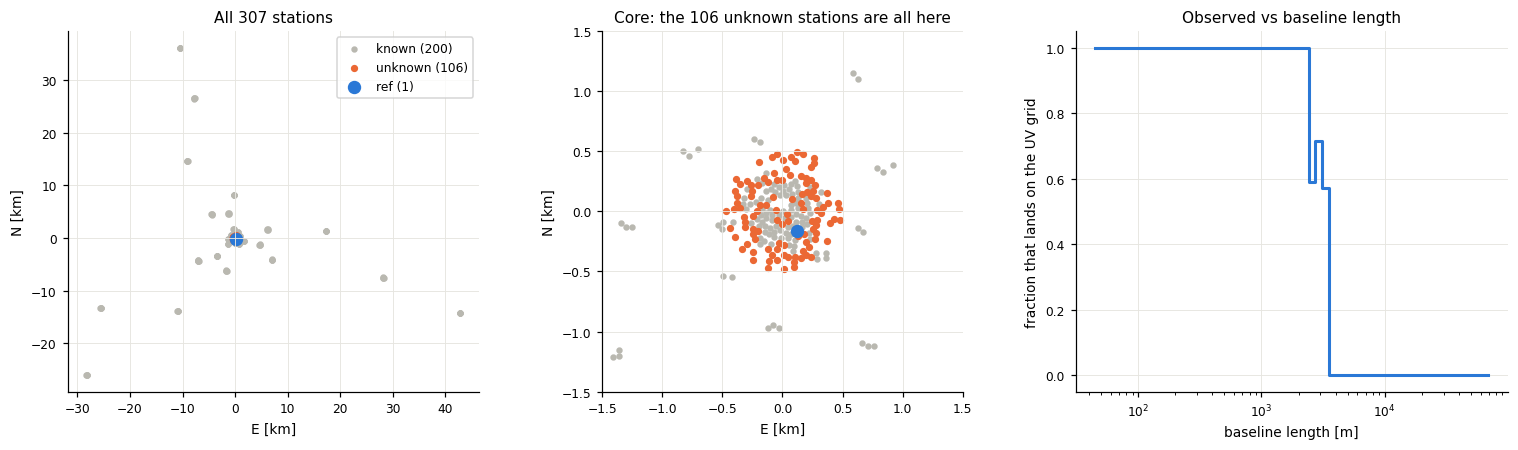

longest observed baseline 3390 m, shortest unobserved 2673 m
baselines with station 0 that are observed: 230 of 306


In [5]:
layout = np.loadtxt(ROOT / "src/skalow_AAstar_layout.txt")           # (307, 3) station E, N, U [m]
assert len(layout) == NANT
Ii, Jj = I.cpu().numpy(), J.cpu().numpy()
bl_len = np.hypot(*(layout[Ii, :2] - layout[Jj, :2]).T)              # [m]
obs = observed_bl.cpu().numpy()

role = np.full(NANT, "known", dtype=object); role[0] = "ref"; role[1:1 + N_UNK] = "unknown"
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
for r, c, s in (("known", "#b9b8b0", 10), ("unknown", C_MINE, 14), ("ref", C_DATA, 60)):
    m = role == r
    ax[0].scatter(layout[m, 0] / 1e3, layout[m, 1] / 1e3, s=s, c=c, label=f"{r} ({m.sum()})")
ax[0].set(xlabel="E [km]", ylabel="N [km]", title="All 307 stations", aspect="equal"); ax[0].legend()
for r, c, s in (("known", "#b9b8b0", 10), ("unknown", C_MINE, 14), ("ref", C_DATA, 60)):
    m = role == r
    ax[1].scatter(layout[m, 0] / 1e3, layout[m, 1] / 1e3, s=s, c=c)
ax[1].set(xlim=(-1.5, 1.5), ylim=(-1.5, 1.5), xlabel="E [km]", ylabel="N [km]", aspect="equal",
          title="Core: the 106 unknown stations are all here")

bins = np.logspace(np.log10(bl_len.min()), np.log10(bl_len.max()), 60)
tot, _ = np.histogram(bl_len, bins); hit, _ = np.histogram(bl_len[obs], bins)
ax[2].semilogx(np.sqrt(bins[1:] * bins[:-1]), hit / np.maximum(tot, 1), color=C_DATA, drawstyle="steps-mid")
ax[2].set(xlabel="baseline length [m]", ylabel="fraction that lands on the UV grid",
          title="Observed vs baseline length")
plt.tight_layout(); plt.show()

print(f"longest observed baseline {bl_len[obs].max():.0f} m, shortest unobserved {bl_len[~obs].min():.0f} m")
print(f"baselines with station 0 that are observed: {obs[Ii == 0].sum()} of {NANT - 1}")

**What we see.** Every baseline shorter than 2.67 km lands on the grid and none longer than 3.39 km
does. In between it depends on orientation: the grid is square, so along a diagonal it reaches √2
further than along an axis (and Earth rotation turns the baseline during the 4 h). The 20 246
unobserved baselines are those involving the outer stations. The reference station 0 has 230 observed
baselines — the "first row" that Stage 1 reads. All 106 unknown stations sit within 590 m of the
array centre, so every one of them has an observed baseline with station 0.

## 3. Truth → gains (`GainsFromZ`)

`z` holds the 212 real numbers that falcon infers: interleaved `(Re, Im)` perturbations of the 106
unknown stations. The truth is `z ~ N(0, 0.3²)` drawn with seed 99. The gains are

* station 0 (reference): `g₀ = 1` exactly (fixes the overall phase, which visibilities cannot see),
* stations 1–106: `g = (1 + z_re) + i z_im`,
* stations 107–306 (known): `g = 1`.

z  (seed 99 redraw)    max|mine − data| = 0.000e+00   (max|data| = 9.292e-01)   BIT-IDENTICAL


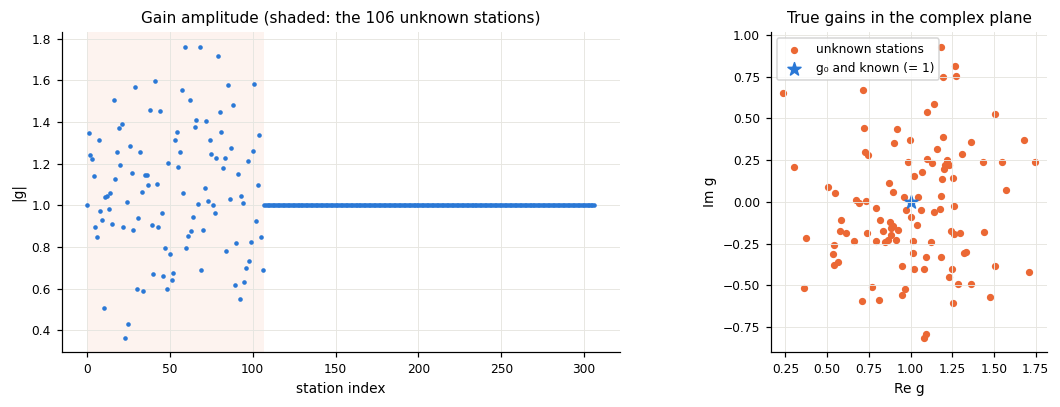

|g| of unknown stations: 0.366 … 1.761;  phase: -55° … 70°


In [6]:
z_true = torch.tensor(D["true_z"], device=DEV)                       # (1, 212)
# redraw it from the seed exactly as settings.true_z does (a private generator)
z_redraw = torch.randn(1, 2 * N_UNK, generator=torch.Generator().manual_seed(Z_SEED)) * Z_SCALE
compare("z  (seed 99 redraw)", z_redraw, D["true_z"])

g = torch.ones(NANT, dtype=torch.complex64, device=DEV)
g[1:1 + N_UNK] = torch.complex(1 + z_true[0, 0::2], z_true[0, 1::2])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(g.abs().cpu(), ".", color=C_DATA, ms=4)
ax[0].axvspan(0.5, N_UNK + 0.5, color=C_MINE, alpha=0.08, lw=0)
ax[0].set(xlabel="station index", ylabel="|g|", title="Gain amplitude (shaded: the 106 unknown stations)")
gc = g[1:1 + N_UNK].cpu()
ax[1].scatter(gc.real, gc.imag, s=14, color=C_MINE, label="unknown stations")
ax[1].scatter([1], [0], s=80, color=C_DATA, marker="*", label="g₀ and known (= 1)")
ax[1].set(xlabel="Re g", ylabel="Im g", title="True gains in the complex plane", aspect="equal"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"|g| of unknown stations: {gc.abs().min():.3f} … {gc.abs().max():.3f};  phase: "
      f"{np.degrees(gc.angle().min().item()):.0f}° … {np.degrees(gc.angle().max().item()):.0f}°")

Every baseline (i, j) sees the product `g_i · conj(g_j)`, in the same `triu_indices` order as the
tracks file. Baselines between two known stations (or known + reference) have product exactly 1 —
these are the majority, which matters later: the UV maps mix "clean" and "corrupted" baselines.

In [7]:
bg = g[I] * g[J].conj()                                              # (K,) complex
unk = (I >= 1) & (I <= N_UNK), (J >= 1) & (J <= N_UNK)
cls = {"no unknown station": ~unk[0] & ~unk[1], "one unknown": unk[0] ^ unk[1], "two unknown": unk[0] & unk[1]}
for name, m in cls.items():
    print(f"{name:20s}: {m.sum().item():6d} baselines, of which observed {(m & observed_bl).sum().item():6d};"
          f"  |g_i g_j*| range {bg[m].abs().min():.3f}–{bg[m].abs().max():.3f}")

no unknown station  :  20100 baselines, of which observed   7910;  |g_i g_j*| range 1.000–1.000
one unknown         :  21306 baselines, of which observed  13250;  |g_i g_j*| range 0.366–1.761
two unknown         :   5565 baselines, of which observed   5565;  |g_i g_j*| range 0.157–3.099


## 4. Truth → density field δ (`DensityFromPw`)

The power spectrum is a broken power law, continuous at the break,

$$P(k) = A\,(k/k_b)^{n_1}\ (k \le k_b),\qquad A\,(k/k_b)^{n_2}\ (k>k_b),\qquad P(0)=0 .$$

The field is drawn in Fourier space: real white noise `w ~ N(0,1)` (seed 54, 128×128) →
`rfft2(w, ortho)` is Hermitian with unit power per mode → multiply by `sqrt(P(k) / (dx dy))` →
`irfft2(…, ortho)`. The division by `dx dy` is the convention that makes the estimator below
(`|δ̃|² dx dy`) return exactly `P(k)` on average.

The `|k|` grid uses `rfftfreq` along x (columns, 65 values) and `fftfreq` along y (rows, 128 values),
times 2π / pixel size.

In [8]:
log_A, n1, n2, log_kb = D["true_pw"][0]
A  = torch.pow(10, torch.tensor([log_A],  dtype=torch.float32, device=DEV))   # same float32 path as model.py
kb = torch.pow(10, torch.tensor([log_kb], dtype=torch.float32, device=DEV))
n1 = torch.tensor([n1], dtype=torch.float32, device=DEV); n2 = torch.tensor([n2], dtype=torch.float32, device=DEV)

def kgrid(rfft):
    kx = (torch.fft.rfftfreq if rfft else torch.fft.fftfreq)(N_PIX, d=DX, device=DEV) * 2 * np.pi
    ky = torch.fft.fftfreq(N_PIX, d=DX, device=DEV) * 2 * np.pi
    KX, KY = torch.meshgrid(kx, ky, indexing="xy")                   # array[y, x]
    return torch.sqrt(KX ** 2 + KY ** 2)

k_r = kgrid(rfft=True)                                               # (128, 65)
print(f"k grid {tuple(k_r.shape)}: k_min = {k_r[k_r > 0].min():.4f}, k_Nyq = {np.pi / DX:.4f}, "
      f"k_max (corner) = {k_r.max():.4f} Mpc⁻¹;  k_break = {kb.item():.4f}")

def broken_pl(k):
    k_safe = torch.where(k < 1e-12, torch.ones_like(k), k)
    r = k_safe / kb[:, None, None]
    P = torch.where(k_safe <= kb[:, None, None], A[:, None, None] * r ** n1[:, None, None],
                    A[:, None, None] * r ** n2[:, None, None])
    return torch.where(k < 1e-12, torch.zeros_like(P), P)

P_grid = broken_pl(k_r)                                              # (1, 128, 65) [Mpc²]

torch.manual_seed(FIELD_SEED)                                        # reseeds the GLOBAL generator, as model does
white = torch.randn((1, N_PIX, N_PIX), device=DEV)
w_k = torch.fft.rfft2(white, norm="ortho")                           # Hermitian, E|w_k|² = 1
delta = torch.fft.irfft2(w_k * torch.sqrt(P_grid / (DX * DX)), s=(N_PIX, N_PIX), norm="ortho")
compare("δ  (true_delta)", delta, D["true_delta"])
print(f"δ: mean {delta.mean():.2e} (P(0)=0 → zero DC), std {delta.std():.4f}, range {delta.min():.3f} … {delta.max():.3f}")

k grid (128, 65): k_min = 0.0123, k_Nyq = 0.7854, k_max (corner) = 1.1107 Mpc⁻¹;  k_break = 0.5012
δ  (true_delta)        max|mine − data| = 0.000e+00   (max|data| = 2.104e-01)   BIT-IDENTICAL
δ: mean -8.73e-11 (P(0)=0 → zero DC), std 0.0564, range -0.210 … 0.203


### The P(k) estimator (`PowerSpectrumMeasurer`)

We need it for δ now and for the dirty images later. Recipe: subtract the mean; `rfft2(·, ortho)`;
`P = |δ̃|² · dx dy` per mode; average modes into 50 **log-spaced** bins between the smallest non-zero
`|k|` and the corner `|k|` (bins are half-open `(e_b, e_b+1]`, DC excluded). Log bins are narrower
than the grid spacing at low k, so some low-k bins contain **no mode** → NaN.

Note it works on the half-plane (rfft), so each mode is counted once *per rfft cell*, including the
x = 0 and x = Nyquist columns that are their own mirror — the same as the project code.

In [9]:
k_flat = k_r.reshape(-1)
edges = torch.logspace(np.log10(k_flat[k_flat > 0].min().item()), np.log10(k_flat.max().item()),
                       steps=N_BINS + 1, device=DEV)
k_centres = 0.5 * (edges[:-1] + edges[1:])
b_idx = torch.bucketize(k_flat, edges) - 1                           # DC → −1
lost = ((k_flat > 0) & (b_idx < 0)).sum().item()
b_idx[(k_flat > 0) & (b_idx < 0)] = 0                                # guard for logspace round-off at k_min
valid = ((b_idx >= 0) & (b_idx < N_BINS)).float()
b_idx = b_idx.clamp(0, N_BINS - 1)
modes = torch.zeros(N_BINS, device=DEV).scatter_add_(0, b_idx, valid)
empty = modes < 1
print(f"k_min-ring modes the guard rescued: {lost} (it is a no-op on this grid)")
print(f"empty bins (no mode): {empty.nonzero().flatten().tolist()};  modes in first 10 bins: {modes[:10].int().tolist()}")

def measure_pk(images):
    images = images.contiguous()                                     # see the note in step 10
    images = images - images.mean(dim=(-2, -1), keepdim=True)
    p = (torch.fft.rfft2(images, norm="ortho").abs() ** 2 * DX * DX).reshape(len(images), -1) * valid
    s = torch.zeros(len(images), N_BINS, device=DEV).scatter_add_(1, b_idx.expand(len(images), -1), p)
    pk = s / modes.clamp(min=1)
    pk[:, empty] = float("nan")
    return pk

pk_delta = measure_pk(delta)[0]
compare("k-bin centres", k_centres, D["true_k"])
compare("P(k) of δ", pk_delta, D["true_pk_measured"])

k_min-ring modes the guard rescued: 0 (it is a no-op on this grid)
empty bins (no mode): [1, 2, 4, 5, 6, 9, 10, 13];  modes in first 10 bins: [3, 0, 0, 2, 0, 0, 0, 3, 4, 0]
k-bin centres          max|mine − data| = 0.000e+00   (max|data| = 1.063e+00)   BIT-IDENTICAL
P(k) of δ              max|mine − data| = 0.000e+00   (max|data| = 3.180e+01)   BIT-IDENTICAL


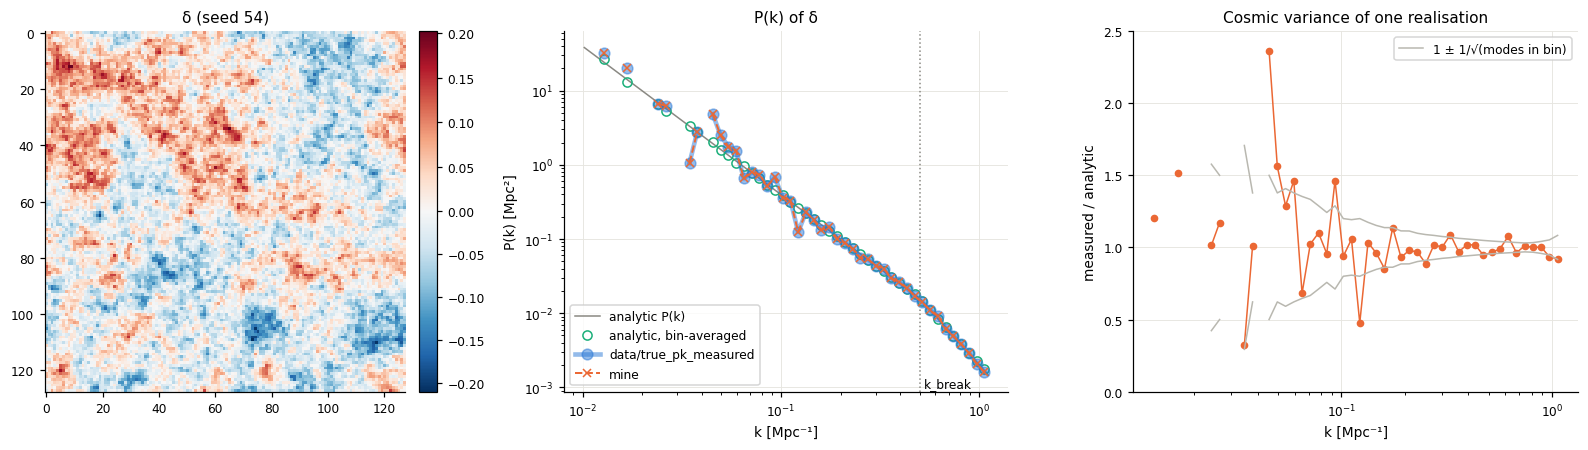

In [10]:
kc = k_centres.cpu().numpy()
P_analytic_bins = (P_grid.reshape(-1) * valid).new_zeros(N_BINS).scatter_add_(0, b_idx, (P_grid.reshape(-1) * valid)) / modes.clamp(min=1)
P_analytic_bins[empty] = float("nan")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
show(ax[0], delta[0].cpu(), "δ (seed 54)", cmap="RdBu_r", norm=TwoSlopeNorm(0))
kk = np.logspace(np.log10(kc[0]) - 0.1, np.log10(k_r.max().item()), 300)
P_line = broken_pl(torch.tensor(kk, dtype=torch.float32, device=DEV)[None, None, :])[0, 0].cpu()
ax[1].loglog(kk, P_line, color="#8a8983", lw=1, label="analytic P(k)")
ax[1].loglog(kc, P_analytic_bins.cpu(), "o", mfc="none", color=C_3, ms=6, label="analytic, bin-averaged")
ax[1].loglog(kc, D["true_pk_measured"], "o-", color=C_DATA, lw=3, ms=7, alpha=0.5, label="data/true_pk_measured")
ax[1].loglog(kc, pk_delta.cpu(), "x--", color=C_MINE, ms=5, lw=1.3, label="mine")
ax[1].axvline(kb.item(), color="#8a8983", ls=":", lw=1); ax[1].text(kb.item() * 1.05, 1e-3, "k_break", fontsize=8)
ax[1].set(xlabel="k [Mpc⁻¹]", ylabel="P(k) [Mpc²]", title="P(k) of δ"); ax[1].legend()
ratio = pk_delta.cpu() / P_analytic_bins.cpu()
sig = 1 / np.sqrt(np.where(empty.cpu().numpy(), np.nan, modes.cpu().numpy()))   # NaN on empty bins
ax[2].semilogx(kc, ratio, "o-", color=C_MINE, ms=4, lw=1)
ax[2].semilogx(kc, 1 + sig, color="#b9b8b0", lw=1, label="1 ± 1/√(modes in bin)")
ax[2].semilogx(kc, 1 - sig, color="#b9b8b0", lw=1)
ax[2].set(xlabel="k [Mpc⁻¹]", ylabel="measured / analytic", title="Cosmic variance of one realisation",
          ylim=(0, 2.5)); ax[2].legend()
plt.tight_layout(); plt.show()

**What we see.** The measured P(k) of this single realisation scatters around the analytic one
with the expected cosmic variance (each mode's power is exponentially distributed, so a bin with *n*
modes scatters by ~1/√n, grey band = ±1σ): factors of 2–3 at low k (2–10 modes per bin), a few % at
high k. Gaps
are the empty low-k bins. Mine and `data/` lie on top of each other (bit-identical).

## 5. δ → brightness temperature → sky image (`BrightnessFromDensity`, `SkyImageFromBrightness`)

$$T_b = T_0\,x_{HI}\,(1+\delta)\,(1 - T_{CMB}/T_S),\qquad
T_0 = \frac{3\,h_P\,c^3 A_{10}\,n_H(z)}{32\pi\,k_B\,\nu_{21}^2\,(1+z)\,H(z)},\qquad
n_H(z) = \frac{(1-Y_p)\,\Omega_b\,\rho_{crit,0}\,(1+z)^3}{m_p}$$

(optically thin, no peculiar velocities; Furlanetto, Oh & Briggs 2006, with `A10 = 2.85e-15 s⁻¹` and
`H(z)` of flat ΛCDM). The project uses Planck 2018 (`h = 0.674, Ω_m = 0.315, Ω_b = 0.0492, Y_p = 0.2454`),
fully neutral (`x_HI = 1`) with `T_S ≫ T_CMB` (`T_CMB = 0, T_S = 1`), at z = 9, so
`T_b = T0 (1 + δ)` with `T0 = 26.602` mK (Furlanetto's approximation `27 (Ω_b h²/0.023)(0.15/Ω_m h² · (1+z)/10)^½`
gives 26.86 mK). The science image adds
`FOREGROUND × (calibrator Gaussian)`, and `FOREGROUND = 0`, so `image = T_b`.

In [11]:
x_HI, T_CMB, T_S, Om_b, h, Om_m, Y_p = 1.0, 0.0, 1.0, OM_B, H_LITTLE, OM_M, Y_P
h_P, c_SI, k_B, A10, nu21 = 6.62607015e-34, 2.99792458e8, 1.380649e-23, 2.85e-15, 1420.405751768e6
m_p, G_N, Mpc = 1.67262192369e-27, 6.67430e-11, 3.0856775814913673e22    # SI
H0 = 100e3 * h / Mpc                                                       # [1/s]
rho_crit = 3.0 * H0 ** 2 / (8.0 * np.pi * G_N)                             # [kg/m³]
n_H = (1.0 - Y_p) * Om_b * rho_crit / m_p * (1.0 + REDSHIFT) ** 3          # [1/m³]
H_z = H0 * np.sqrt(Om_m * (1.0 + REDSHIFT) ** 3 + 1.0 - Om_m)              # [1/s]
T0 = 3.0 * h_P * c_SI ** 3 * A10 * n_H / (32.0 * np.pi * k_B * nu21 ** 2 * (1.0 + REDSHIFT) * H_z) * 1e3
T_b = T0 * x_HI * (1 - T_CMB / T_S) * (1 + delta)

def gaussian(sigma):                                                 # unit peak, centred ON pixel (64, 64)
    c = torch.arange(N_PIX, dtype=torch.float32, device=DEV)
    X, Y = torch.meshgrid(c, c, indexing="xy")
    return torch.exp(-((X - N_PIX // 2) ** 2 + (Y - N_PIX // 2) ** 2) / (2 * sigma ** 2))

image = T_b + FOREGROUND * gaussian(CAL_SIGMA)[None]
compare("image", image[0], D["image"])
print(f"T0 = {T0:.4f} mK;  image: mean {image.mean():.4f} mK (= T0 × (1 + mean δ)), std {image.std():.3f} mK")

product of cosmology factors = 1.0002299355467712
image                  max|mine − data| = 0.000e+00   (max|data| = 3.248e+01)   BIT-IDENTICAL
T0 = 27.0062 mK;  image: mean 27.0062 mK (= T0 × (1 + mean δ)), std 1.524 mK


## 6. Sky → Fourier sky (`UVSkyFromImage`)

`uvimage = fft2(ifftshift(image), ortho)`. The `ifftshift` moves the beam/phase centre (pixel 64, 64)
to `[0, 0]` before the FFT, so a source at the beam centre has zero phase on every baseline; the
result is in FFT order, like the tracks. `ortho` keeps mK units: the DC pixel equals
`Σ image / 128 = 128 × mean`.

In [12]:
def image_to_uv(img):
    return torch.fft.fft2(torch.fft.ifftshift(img, dim=(-2, -1)), norm="ortho")

def uv_to_image(uv):
    return torch.fft.fftshift(torch.fft.ifft2(uv, norm="ortho"), dim=(-2, -1))

uvimage = image_to_uv(image)                                         # (1, 128, 128) complex
print(f"DC = {uvimage[0, 0, 0].real:.3f}  vs  128 × mean = {N_PIX * image.mean():.3f}")
print("round trip max error:", (uv_to_image(uvimage).real - image).abs().max().item())

DC = 3456.794  vs  128 × mean = 3456.795
round trip max error: 1.1444091796875e-05


## 7. Gridding the baselines: UV coverage and gain-weighted UV maps (`UVTracksFromGains`)

The baselines are split into **2 contiguous halves** of the `triu` order (23 486 and 23 485) — one
UV map each. In `triu` order the first half holds the baselines whose first station is i = 0…89, so
**subset 0 is almost entirely baselines that touch an unknown station** (16 558 of its 16 682
observed ones), while subset 1 (i = 89…305) is mostly known–known plus the baselines of unknown
stations 89–106 (2 257 observed). The split is by index, not by geometry, so the two subsets also
cover the UV plane differently (printed below).

For one subset, each UV pixel receives

$$\text{stacked}[y,x] = \sum_{\text{baselines}}\ \sum_{\text{track samples in }(y,x)} t \cdot g_i\,g_j^*,$$

and each baseline is gridded a second time at the mirrored pixel `(−y, −x)` with `conj(g_i g_j*)`
(the visibility of the reversed baseline j–i), which makes the map **Hermitian** → real images.
Samples that land on the DC pixel get zero weight (so dirty images have zero mean). With unit gains
the same sum is simply the **number of integrations per pixel** — the normalisation.

In [13]:
sizes = [K // N_SUBSETS + (1 if s < K % N_SUBSETS else 0) for s in range(N_SUBSETS)]
subsets = list(torch.split(torch.arange(K, device=DEV), sizes))
print("subset sizes:", sizes)
for s, idx in enumerate(subsets):
    m_unk = unk[0][idx] | unk[1][idx]
    print(f"  subset {s}: first station i = {I[idx].min().item()}…{I[idx].max().item()};  "
          f"observed baselines {observed_bl[idx].sum().item()};  observed with an unknown station "
          f"{(m_unk & observed_bl[idx]).sum().item()}")

def grid_subset(weights, idx):
    sel = padded[idx]
    x, y = sel[:, 0].long(), sel[:, 1].long()
    t = sel[:, 2] * ((x != 0) | (y != 0))                            # drop the DC pixel
    w = weights[idx]
    vals = torch.cat([(w[:, None] * t.to(w.dtype)).reshape(-1),         # baseline (i, j) at (y, x)
                      (w.conj()[:, None] * t.to(w.dtype)).reshape(-1)]) # mirror (j, i) at (−y, −x)
    pix = torch.cat([(y * N_PIX + x).reshape(-1), (((-y) % N_PIX) * N_PIX + (-x) % N_PIX).reshape(-1)])
    out = torch.zeros(1, N_PIX * N_PIX, dtype=w.dtype, device=DEV)
    out.scatter_add_(1, pix[None], vals[None])                       # padded zeros (t = 0) add nothing
    return out.view(N_PIX, N_PIX)

stacked_uv = torch.stack([grid_subset(bg, idx) for idx in subsets])[None]          # (1, 2, 128, 128)
unit_uv = torch.stack([grid_subset(torch.ones_like(bg), idx) for idx in subsets])[None]
counts = unit_uv.real
for s in range(N_SUBSETS):
    c = counts[0, s]
    print(f"subset {s}: {(c > 0).sum().item()} of {N_PIX**2} UV cells sampled ({(c > 0).float().mean():.1%}),"
          f"  Hermitian: {torch.equal(c, torch.roll(c.flip(0, 1), (1, 1), (0, 1)))}")
both = ((counts[0, 0] > 0) | (counts[0, 1] > 0)).float().mean()
print(f"union of both subsets: {both:.1%} of cells")

subset sizes: [23486, 23485]
  subset 0: first station i = 0…89;  observed baselines 16682;  observed with an unknown station 16558
  subset 1: first station i = 89…305;  observed baselines 10043;  observed with an unknown station 2257


subset 0: 9840 of 16384 UV cells sampled (60.1%),  Hermitian: True
subset 1: 12498 of 16384 UV cells sampled (76.3%),  Hermitian: True
union of both subsets: 76.5% of cells


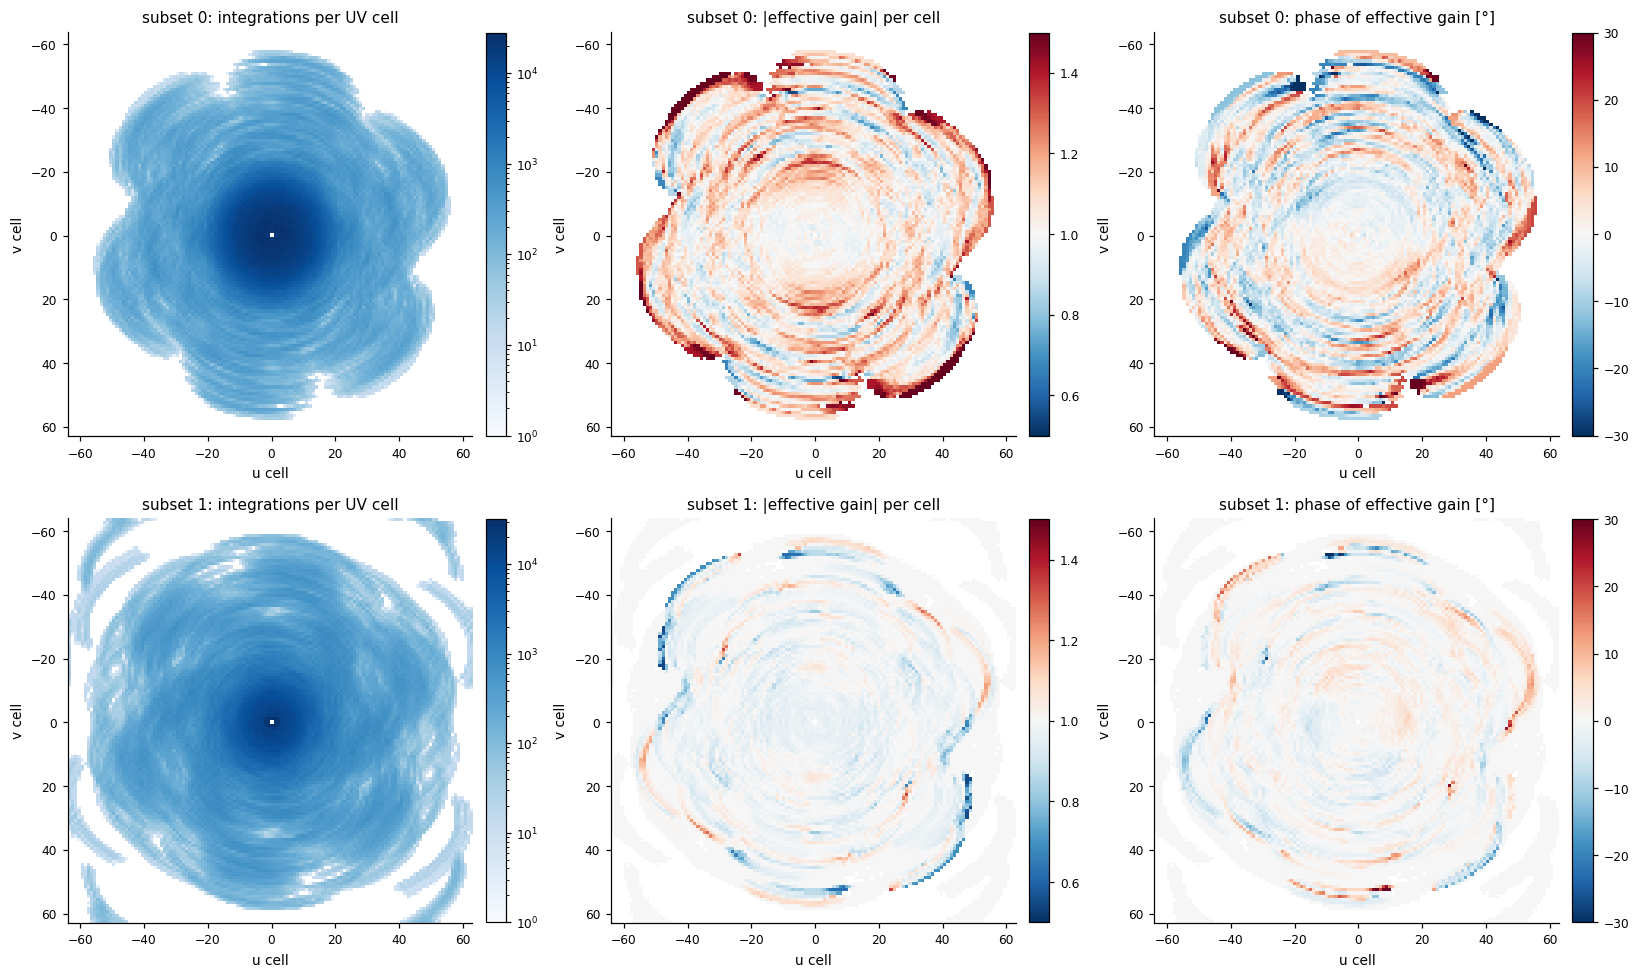

subset 0: |geff − 1| median 0.139, max 0.947
subset 1: |geff − 1| median 0.026, max 0.558


In [14]:
# effective gain per UV pixel = (Σ t g_i g_j*) / (Σ t): the integration-weighted mean gain product
geff = torch.where(counts > 0, stacked_uv / unit_uv, torch.zeros_like(stacked_uv))
sh = lambda a: np.fft.fftshift(a.cpu().numpy(), axes=(-2, -1))       # display only: DC in the middle
ext = [-64, 63, 63, -64]
fig, ax = plt.subplots(2, 3, figsize=(15, 9))
for s in range(2):
    show(ax[s, 0], np.where(sh(counts[0, s]) > 0, sh(counts[0, s]), np.nan), f"subset {s}: integrations per UV cell",
         norm=LogNorm(), extent=ext)
    show(ax[s, 1], np.where(sh(counts[0, s]) > 0, sh(geff[0, s].abs()), np.nan),
         f"subset {s}: |effective gain| per cell", cmap="RdBu_r", norm=TwoSlopeNorm(1, 0.5, 1.5), extent=ext)
    show(ax[s, 2], np.where(sh(counts[0, s]) > 0, np.degrees(sh(geff[0, s].angle())), np.nan),
         f"subset {s}: phase of effective gain [°]", cmap="RdBu_r", norm=TwoSlopeNorm(0, -30, 30), extent=ext)
for a in ax.flat:
    a.set(xlabel="u cell", ylabel="v cell")
plt.tight_layout(); plt.show()
m0 = counts[0, 0] > 0
print(f"subset 0: |geff − 1| median {(geff[0,0][m0]-1).abs().median():.3f}, max {(geff[0,0][m0]-1).abs().max():.3f}")
m1 = counts[0, 1] > 0
print(f"subset 1: |geff − 1| median {(geff[0,1][m1]-1).abs().median():.3f}, max {(geff[0,1][m1]-1).abs().max():.3f}")

**What we see.** Left: the UV coverage — dense in the centre (short core baselines, thousands of
integrations), thinning towards the edge, point-symmetric because of the mirrored copies. Subset 0
(core stations only as first index) covers 60 % of the cells, subset 1 76 % including outer arcs.
Middle and right: the **effective gain** each UV cell applies to the sky. Single gain products range
0.16–3.1 in amplitude, but a cell averages `g_i g_j*` over many baselines, so errors partly cancel:
in subset 0 the typical cell is off by 14 % (median |g_eff − 1|), close to 1 in the dense centre and
far off (red/blue rims) at the edge where only a few baselines contribute. In subset 1, where most
baselines are known–known (exactly 1), the typical cell is off by only 2.6 %.

## 8. Sampling the sky and normalising (`TrackedUVFromSky`, `NormalisedUV`)

`tracked_uv = stacked_uv × uvimage` (every subset multiplies the same Fourier sky), then
`normed = tracked_uv / unit_uv`, with `0/0 = NaN → 0` on unsampled cells. Together:

$$x[y,x] = g_\text{eff}[y,x]\cdot \tilde I[y,x]\quad\text{on sampled cells, } 0 \text{ elsewhere}.$$

Dividing by the integration count means each cell holds the *mean* visibility over its
integrations: the signal does not depend on how long a cell was observed (only the noise would).

In [15]:
tracked_uv = stacked_uv * uvimage[:, None]                           # (1, 2, 128, 128)
normed_uv = (tracked_uv / unit_uv).nan_to_num(nan=0.0)               # unsampled: 0/0 → 0
print("normed == geff × uvimage on sampled cells:",
      torch.allclose(normed_uv, geff * uvimage[:, None], rtol=1e-5, atol=1e-6))

normed == geff × uvimage on sampled cells: True


## 9. Thermal noise and the observed UV maps (`ThermalNoiseUV`, `VisibilitiesWithNoise`)

The noise model is `fft2(white, ortho) × NOISE_STD / √(integrations per cell)` — Hermitian, zero on
unsampled cells. With `NOISE_STD = 0` it is identically zero, so `x = normed_uv`. (The model still
draws `randn` for it; that consumes random numbers *after* the seeded field, so it changes nothing.)

In [16]:
noise_scale = torch.where(counts > 0, counts.clamp(min=1e-30).rsqrt(), torch.zeros_like(counts))
noise_uv = torch.fft.fft2(torch.randn(1, N_SUBSETS, N_PIX, N_PIX, device=DEV), norm="ortho") * (NOISE_STD * noise_scale)
x_uv = normed_uv + noise_uv
print("max |noise| =", noise_uv.abs().max().item())
compare("x  (x_obs)", x_uv[0], D["x_obs"])

max |noise| = 0.0
x  (x_obs)             max|mine − data| = 0.000e+00   (max|data| = 4.318e+01)   BIT-IDENTICAL


## 10. Dirty images (`DirtyImageFromUV`)

`obsx = real(fftshift(ifft2(x, ortho)))`. Since `x` is Hermitian, the imaginary part is only FFT
round-off and is discarded. The dirty image is the true sky convolved with the PSF of each subset
(and modulated by the effective gains), minus its mean (the DC cell was dropped).

max |Im| / max |Re| = 1.7e-07  (round-off)
obsx  (obsx_obs)       max|mine − data| = 0.000e+00   (max|data| = 5.772e+00)   BIT-IDENTICAL


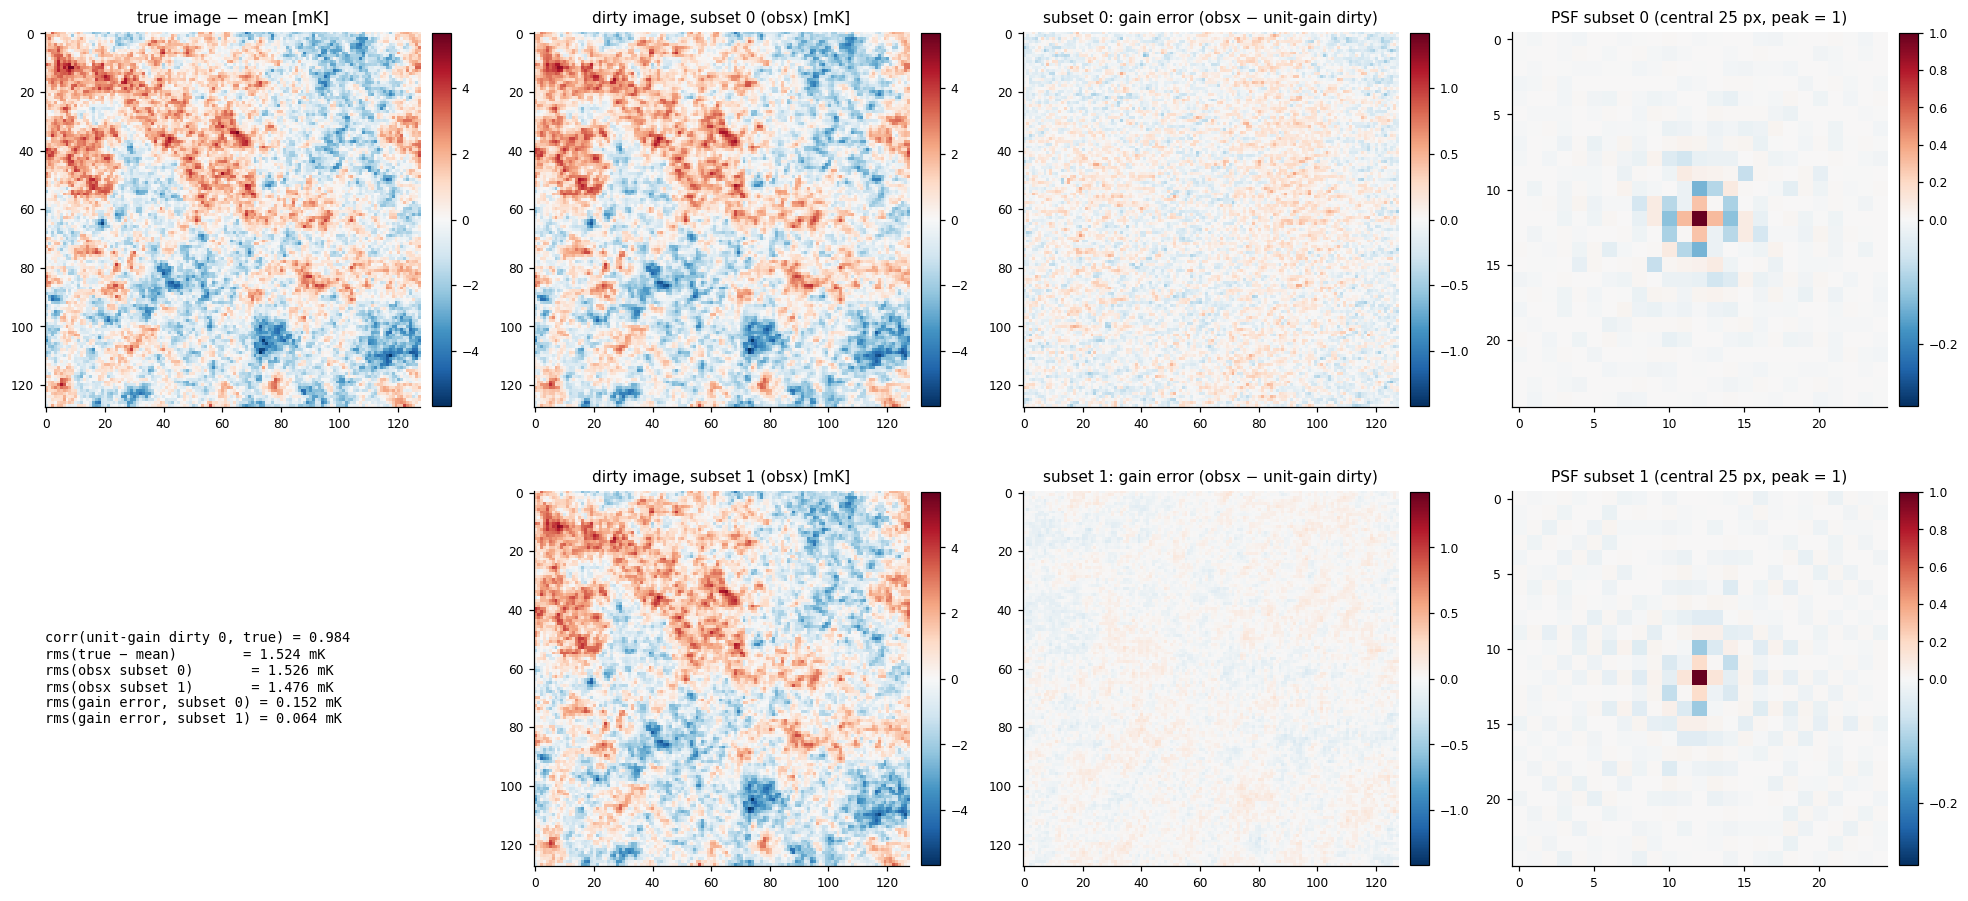

In [17]:
dirty_c = uv_to_image(x_uv)
print(f"max |Im| / max |Re| = {(dirty_c.imag.abs().max() / dirty_c.real.abs().max()).item():.1e}  (round-off)")
obsx = dirty_c.real
compare("obsx  (obsx_obs)", obsx[0], D["obsx_obs"])

# two references to separate the two effects: sampling only (unit gains) and the true sky itself
x_unitgain = torch.where(counts > 0, uvimage[:, None].expand_as(counts), torch.zeros_like(x_uv))
obsx_unitgain = uv_to_image(x_unitgain).real
psf = uv_to_image(torch.where(counts > 0, 1.0 + 0j, 0j)).real          # dirty beam per subset

img0 = (image - image.mean())[0].cpu()
vmax = img0.abs().max().item()
fig, ax = plt.subplots(2, 4, figsize=(18, 8.5))
show(ax[0, 0], img0, "true image − mean [mK]", cmap="RdBu_r", norm=TwoSlopeNorm(0, -vmax, vmax))
for s in range(2):
    show(ax[s, 1], obsx[0, s].cpu(), f"dirty image, subset {s} (obsx) [mK]", cmap="RdBu_r", norm=TwoSlopeNorm(0, -vmax, vmax))
    show(ax[s, 2], (obsx[0, s] - obsx_unitgain[0, s]).cpu(), f"subset {s}: gain error (obsx − unit-gain dirty)",
         cmap="RdBu_r", norm=TwoSlopeNorm(0, -vmax / 4, vmax / 4))
    p = psf[0, s].cpu(); pz = p[64 - 12:64 + 13, 64 - 12:64 + 13]
    show(ax[s, 3], pz / pz.max(), f"PSF subset {s} (central 25 px, peak = 1)", cmap="RdBu_r", norm=TwoSlopeNorm(0, -0.3, 1))
r0 = torch.corrcoef(torch.stack([obsx_unitgain[0, 0].flatten(), (image - image.mean())[0].flatten()]))[0, 1]
ax[1, 0].axis("off")
ax[1, 0].text(0.0, 0.5, "\n".join([
    f"corr(unit-gain dirty 0, true) = {r0:.3f}",
    f"rms(true − mean)        = {img0.std():.3f} mK",
    *[f"rms(obsx subset {s})       = {obsx[0, s].std():.3f} mK" for s in range(2)],
    *[f"rms(gain error, subset {s}) = {(obsx[0, s] - obsx_unitgain[0, s]).std():.3f} mK" for s in range(2)],
]), family="monospace", fontsize=9, va="center")
plt.tight_layout(); plt.show()

**What we see.** The dirty images look like the true sky with the finest detail softened
(correlation 0.98 between the unit-gain dirty image and the truth): the unsampled cells are mostly the
largest |u, v| (the corners of the grid), so the PSF has a one-pixel core with sidelobes of up to
−30 % (subset 0, sparser) and less for subset 1. The gain-error maps (third column, note the 4× smaller
colour scale) are the difference between observing with the true gains and with perfect calibration:
rms 0.15 mK in subset 0 (10 % of the 1.5 mK sky rms) and 0.06 mK in subset 1, noise-like because the
effective-gain errors of step 7 are scattered over many cells.

> **Implementation note (the one thing needed for bit-identity in step 11).** `obsx = dirty_c.real` is
> a *strided view* of a complex tensor. Feeding it to `rfft2` gives results that differ from a
> contiguous copy at the 1e-7 relative level (a different FFT code path). In `gen_mock_data.py` the
> array goes through numpy between nodes, so it is contiguous; `measure_pk` therefore calls
> `.contiguous()`. Without it `pk_obs` agrees to 1.6e-7 relative instead of exactly.

## 11. P(k) of the dirty images → `pk_obs` (`PkFromDirtyImage`) — the Stage-2 data

In [18]:
pk_obs = measure_pk(obsx[0])                                         # (2, 50)
compare("pk_obs", pk_obs, D["pk_obs"])

pk_image = measure_pk(image)[0]                                      # true sky, all modes
pk_unit = measure_pk(obsx_unitgain[0])                               # perfect gains, sampling only
print(f"P(k) of image = T0² × P(k) of δ (T0² = {T0**2:.1f}):",
      np.allclose(np.nan_to_num(pk_image.cpu()), np.nan_to_num(T0 ** 2 * pk_delta.cpu()), rtol=1e-4))

# fraction of the modes in each k-bin that are sampled, per subset (rfft half-plane, like the estimator)
samp = torch.stack([(counts[0, s][:, :N_PIX // 2 + 1] > 0).float().reshape(-1) * valid for s in range(2)])
frac = torch.zeros(2, N_BINS, device=DEV).scatter_add_(1, b_idx.expand(2, -1), samp) / modes.clamp(min=1)
frac[:, empty] = float("nan")

# round-off bins: no sampled mode → only FFT noise (dropped by the embedding, rtol = 1e-11)
peak = np.nanmax(D["pk_obs"], axis=1, keepdims=True)
roundoff = D["pk_obs"] <= 1e-11 * peak
for s in range(2):
    print(f"subset {s}: P_obs / P_unit-gain over bins with data = {np.nanmin(np.where(roundoff[s], np.nan, (pk_obs[s] / pk_unit[s]).cpu())):.3f} … "
          f"{np.nanmax(np.where(roundoff[s], np.nan, (pk_obs[s] / pk_unit[s]).cpu())):.3f}")
    print(f"subset {s}: round-off-only bins {np.where(roundoff[s])[0].tolist()}  (k = {np.round(kc[roundoff[s]], 3).tolist()})")

pk_obs                 max|mine − data| = 0.000e+00   (max|data| = 2.364e+04)   BIT-IDENTICAL
P(k) of image = T0² × P(k) of δ (T0² = 729.3): True
subset 0: P_obs / P_unit-gain over bins with data = 0.964 … 2.278
subset 0: round-off-only bins [46, 47, 48, 49]  (k = [0.8109999895095825, 0.8880000114440918, 0.9710000157356262, 1.062999963760376])
subset 1: P_obs / P_unit-gain over bins with data = 0.902 … 1.000
subset 1: round-off-only bins []  (k = [])


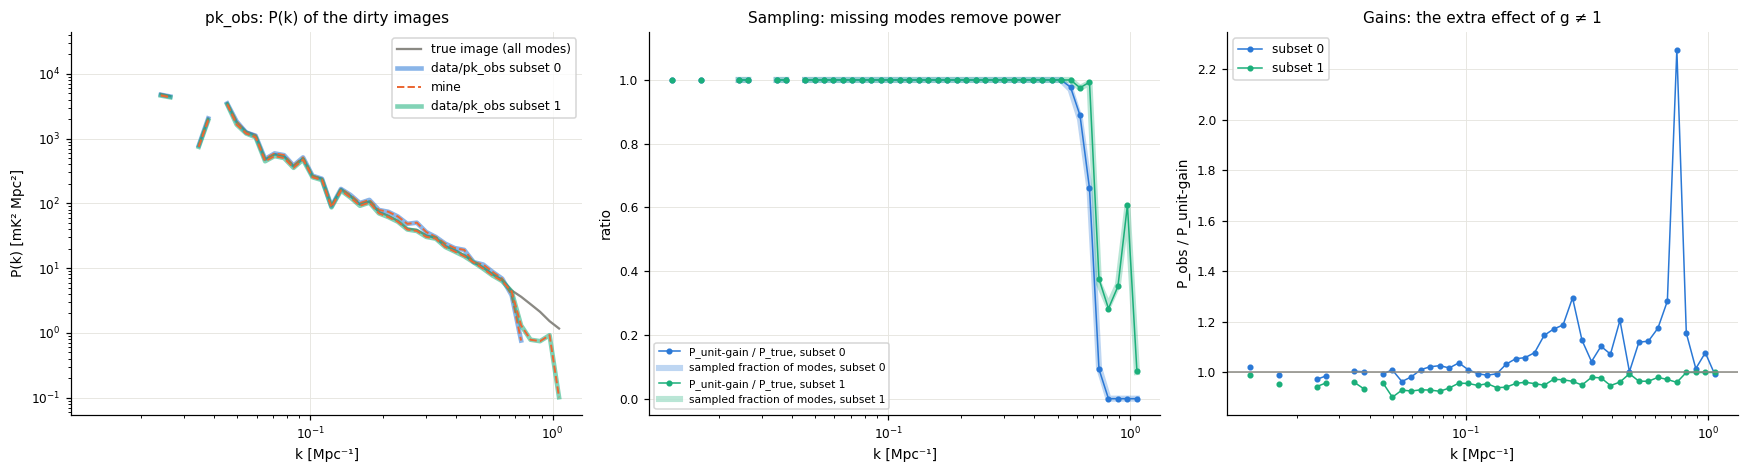

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ax[0].loglog(kc, pk_image.cpu(), color="#8a8983", lw=1.5, label="true image (all modes)")
for s, c in ((0, C_DATA), (1, C_3)):
    good = ~roundoff[s]
    ax[0].loglog(kc[good], D["pk_obs"][s][good], color=c, lw=3, alpha=0.55, label=f"data/pk_obs subset {s}")
    ax[0].loglog(kc[good], pk_obs[s].cpu()[good], "--", color=C_MINE, lw=1.3, label="mine" if s == 0 else None)
ax[0].set(xlabel="k [Mpc⁻¹]", ylabel="P(k) [mK² Mpc²]", title="pk_obs: P(k) of the dirty images"); ax[0].legend()

for s, c in ((0, C_DATA), (1, C_3)):
    ax[1].semilogx(kc, (pk_unit[s] / pk_image).cpu(), "o-", color=c, ms=3, lw=1, label=f"P_unit-gain / P_true, subset {s}")
    ax[1].semilogx(kc, frac[s].cpu(), color=c, lw=4, alpha=0.3, label=f"sampled fraction of modes, subset {s}")
ax[1].set(xlabel="k [Mpc⁻¹]", ylabel="ratio", title="Sampling: missing modes remove power", ylim=(-0.05, 1.15)); ax[1].legend(fontsize=7)

for s, c in ((0, C_DATA), (1, C_3)):
    ax[2].semilogx(kc, (pk_obs[s] / pk_unit[s]).cpu(), "o-", color=c, ms=3, lw=1, label=f"subset {s}")
ax[2].axhline(1, color="#8a8983", lw=1)
ax[2].set(xlabel="k [Mpc⁻¹]", ylabel="P_obs / P_unit-gain", title="Gains: the extra effect of g ≠ 1"); ax[2].legend()
plt.tight_layout(); plt.show()

**What we see — the three factors that make `pk_obs` differ from the true P(k):**

1. **Units / amplitude**: the image is `T0 (1 + δ)` mK with `T0 = 26.602`, so its P(k) is exactly
   `T0² ≈ 707.7` × P(k) of δ (checked above).
2. **Sampling** (middle panel): a dirty image only contains the sampled UV cells; unsampled modes are
   zero but still counted in the bin average. So, with perfect gains, `P_dirty / P_true` follows the
   **fraction of sampled modes per bin** (the thick and dotted curves coincide): exactly 1 up to
   k ≈ 0.57 Mpc⁻¹ (every mode is sampled), then falling as the coverage runs out, and 0 in the 4
   highest bins of subset 0 — those are the **round-off-only bins** listed above, which the Stage-2
   embedding drops.
3. **Gains** (right panel): each mode is multiplied by `|g_eff|²` of its cell. This is **not** a
   negligible effect in subset 0: ≈1 at low k (the dense centre averages many baselines), rising to
   +8–30 % at k ≈ 0.19–0.30 and a spike of ≈2.3 at k ≈ 0.74 where a cell holds only a few baselines.
   Few baselines means no averaging, and on average `|g|²` = 1.25 for these true gains (while
   `|mean g|²` = 1.02), so the power is biased **up**. Subset 1 is biased slightly **down** (0.90–1.0):
   its unknown stations 89–106 happen to have mean |g| = 0.95. So the gains leave a scale-dependent
   imprint in `pk_obs` that is degenerate with the power-spectrum shape — this is exactly why Stage 2
   is given `V_ref`: the gains are encoded there and the flow can undo the bias.

## 12. Calibration path: `S_ref` and `V_ref` (`ReferenceVisFromGains`) — the Stage-1 data

Here the instrument is used in its **dense, per-baseline** form instead of UV maps: each baseline
gets one number, the mean of the Fourier sky over its track,

$$S[i,j] = \frac{\sum_\text{track} t\; \tilde I(+u_{ij})}{\sum_\text{track} t},\qquad S[j,i] = \frac{\sum_\text{track} t\; \tilde I(-u_{ij})}{\sum_\text{track} t},\qquad S[i,i] = 0,$$

each ordered pair on its own track: baseline j–i is the mirrored track, u_ji = −u_ij (as the UV maps grid it
at (−u, −v)). For a real sky Ĩ(−u) = Ĩ(u)*, so S comes out Hermitian without being forced to (checked below).

(zero for baselines that never land on the grid; DC samples dropped as before). The calibrator is a
2.7 mK Gaussian of σ = 0.3 px at the beam centre. Its FFT is real and positive and nearly flat:
`2.7 × Σ(gaussian) / 128 ≈ 0.0214` at the shortest spacings, rolling off slowly because σ = 0.3 px
still leaks ~0.4 % into each neighbour pixel. Then, because the gains are constant over the 4 h,

$$V_\text{ref}[i,j] = g_i\,S_\text{ref}[i,j]\,g_j^* \;(+\ \text{noise, here 0}).$$

In [20]:
xs, ys, ts = padded[:, 0], padded[:, 1], padded[:, 2]
pix_bl = (ys * N_PIX + xs).long()                                    # (K, L): baseline (i, j) at +u
pix_bl_conj = ((-ys) % N_PIX * N_PIX + (-xs) % N_PIX).long()          # baseline (j, i): mirrored, −u
ts = ts * (pix_bl != 0)                                              # drop DC samples
n_bl = ts.sum(-1)
inv_n = torch.where(n_bl > 0, 1.0 / n_bl.clamp(min=1e-30), torch.zeros_like(n_bl))

def sky_matrix(uv):
    v_ij = (uv.reshape(-1)[pix_bl] * ts).sum(-1) * inv_n             # track mean, baseline (i, j)
    v_ji = (uv.reshape(-1)[pix_bl_conj] * ts).sum(-1) * inv_n        # track mean, baseline (j, i)
    M = torch.zeros(NANT, NANT, dtype=v_ij.dtype, device=DEV)
    M[I, J] = v_ij; M[J, I] = v_ji
    return M

cal_image = CAL_FLUX * gaussian(CAL_SIGMA)[None]
S_ref = sky_matrix(image_to_uv(cal_image)[0])
compare("S_ref", S_ref, D["S_ref"])
print(f"Σ gaussian = {gaussian(CAL_SIGMA).sum():.5f};  2.7 × Σ / 128 = {CAL_FLUX * gaussian(CAL_SIGMA).sum() / N_PIX:.5f}")
nz = S_ref[S_ref != 0]
print(f"non-zero S_ref: |S| {nz.abs().min():.5f} … {nz.abs().max():.5f}, max |phase| {nz.angle().abs().max():.1e} rad")

print(f"S_ref Hermitian without being forced: max |S - S^H| = {(S_ref - S_ref.conj().T).abs().max():.1e}")

V_ref = g[:, None] * S_ref * g.conj()[None, :]
compare("V_ref  (V_ref_obs)", V_ref, D["V_ref_obs"])

S_ref                  max|mine − data| = 0.000e+00   (max|data| = 2.142e-02)   BIT-IDENTICAL
Σ gaussian = 1.01552;  2.7 × Σ / 128 = 0.02142
non-zero S_ref: |S| 0.02078 … 0.02142, max |phase| 5.6e-10 rad
S_ref Hermitian without being forced: max |S - S^H| = 5.6e-09
V_ref  (V_ref_obs)     max|mine − data| = 0.000e+00   (max|data| = 6.630e-02)   BIT-IDENTICAL


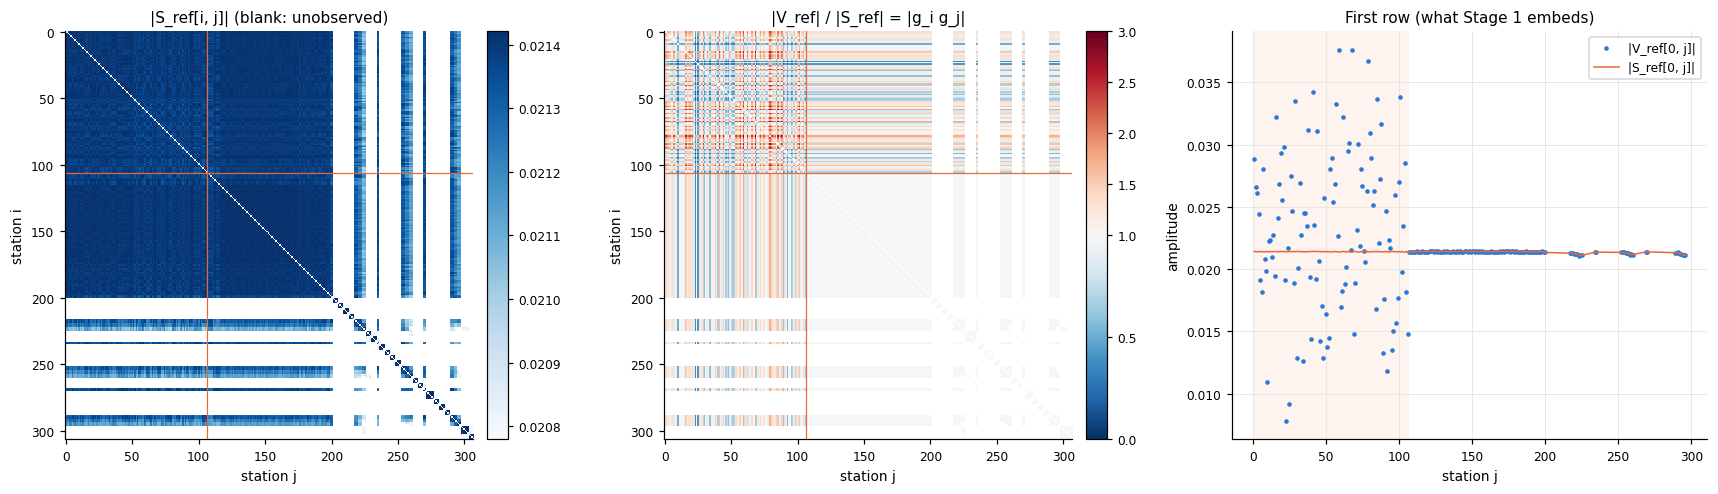

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
show(ax[0], np.where(S_ref.abs().cpu() > 0, S_ref.abs().cpu(), np.nan), "|S_ref[i, j]| (blank: unobserved)", cmap="Blues")
show(ax[1], np.where(V_ref.abs().cpu() > 0, V_ref.abs().cpu() / S_ref.abs().cpu().clamp(min=1e-30), np.nan),
     "|V_ref| / |S_ref| = |g_i g_j|", cmap="RdBu_r", norm=TwoSlopeNorm(1, 0, 3))
for a in ax[:2]:
    a.axhline(N_UNK + 0.5, color=C_MINE, lw=0.8); a.axvline(N_UNK + 0.5, color=C_MINE, lw=0.8)
    a.set(xlabel="station j", ylabel="station i")
row_obs = (S_ref[0, 1:] != 0).cpu().numpy()
jj = np.arange(1, NANT)
ax[2].plot(jj[row_obs], V_ref[0, 1:].abs().cpu()[row_obs], ".", color=C_DATA, ms=4, label="|V_ref[0, j]|")
ax[2].plot(jj[row_obs], S_ref[0, 1:].abs().cpu()[row_obs], color=C_MINE, lw=1, label="|S_ref[0, j]|")
ax[2].axvspan(0.5, N_UNK + 0.5, color=C_MINE, alpha=0.08, lw=0)
ax[2].set(xlabel="station j", ylabel="amplitude", title="First row (what Stage 1 embeds)"); ax[2].legend()
plt.tight_layout(); plt.show()

**What we see.** `S_ref` is ~0.021 on every observed baseline (blank = the long baselines that never
reach the grid). `|V_ref| / |S_ref|` is exactly `|g_i||g_j|`: 1 in the known–known block (bottom
right, beyond the orange line), corrupted wherever an unknown station is involved. The first row is
`V_ref[0, j] = S_ref[0, j] · conj(g_j)` because `g₀ = 1`.

### Closing the loop: the gains are exactly recoverable from `V_ref`

Since `S_ref` is known, `g_j = conj(V_ref[0, j] / S_ref[0, j])` for every station with an observed
baseline to station 0. This is the information Stage 1 has to learn; with noise off it is exact.

z recovered from V_ref max|mine − data| = 1.788e-07   (max|data| = 9.292e-01)   differs


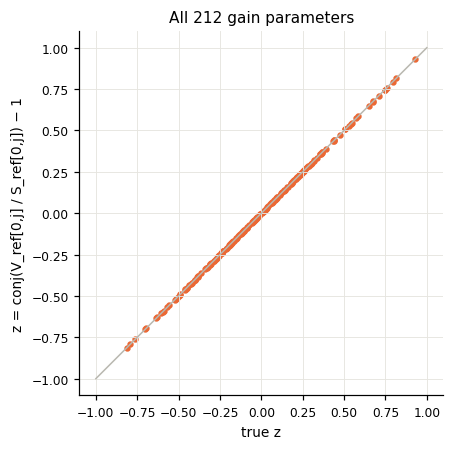

In [22]:
row = torch.tensor(D["V_ref_obs"][0, 1:1 + N_UNK]); srow = torch.tensor(D["S_ref"][0, 1:1 + N_UNK])
g_rec = (row / srow).conj()
z_rec = torch.stack([g_rec.real - 1, g_rec.imag], dim=-1).reshape(1, -1)
compare("z recovered from V_ref", z_rec, D["true_z"])

fig, ax = plt.subplots(figsize=(4.5, 4.2))
ax.plot([-1, 1], [-1, 1], color="#b9b8b0", lw=1)
ax.scatter(D["true_z"][0], z_rec[0], s=10, color=C_MINE)
ax.set(xlabel="true z", ylabel="z = conj(V_ref[0,j] / S_ref[0,j]) − 1", title="All 212 gain parameters", aspect="equal")
plt.tight_layout(); plt.show()

The recovered `z` agree with the truth to ~1e-7 (float32 division), not bit-for-bit — that is
expected, it is a new computation, not a repetition of the simulator's.

## 13. The dense science path (`SkyMatrixFromUVSky`, `DenseVisFromGains`) — auxiliary

`gen_mock_data.py` also stores the 21-cm sky through the dense path: `S_obs = sky_matrix(uvimage)` and
`V_dense = G S_obs G†` (with `G = diag(g)`). falcon does not use these (they are disabled in
`config.yml`), but they show that both instrument forms are fed the same sky.

In [23]:
S_obs = sky_matrix(uvimage[0].to(torch.complex64))
compare("S_obs", S_obs, D["S_obs"])
G = torch.diag_embed(g)
V_dense = G @ S_obs @ G.conj().T
compare("V_dense  (V_dense_obs)", V_dense, D["V_dense_obs"])

# link between the two forms: a baseline that sits in a single UV cell for its whole track has
# S_obs[i, j] exactly equal to that cell of the Fourier sky
one_cell = ((ts > 0).sum(-1) == 1).nonzero().flatten()
b = one_cell[0].item(); p = pix_bl[b][ts[b] > 0][0].item()
print(f"{len(one_cell)} baselines stay in one UV cell; e.g. ({I[b].item()}, {J[b].item()}): "
      f"S_obs = {S_obs[I[b], J[b]].item():.4f},  uvimage at its cell = {uvimage[0].reshape(-1)[p].item():.4f}")

S_obs                  max|mine − data| = 0.000e+00   (max|data| = 4.204e+01)   BIT-IDENTICAL
V_dense  (V_dense_obs) max|mine − data| = 0.000e+00   (max|data| = 9.941e+01)   BIT-IDENTICAL
184 baselines stay in one UV cell; e.g. (0, 2): S_obs = 11.7641+40.3626j,  uvimage at its cell = 11.7641+40.3626j


## 14. Summary

Every product of `scripts/gen_mock_data.py` was rebuilt above with plain torch, without importing
`functionlistnew` or `model`:

In [24]:
print(f"{'quantity':24s} {'shape':16s} {'max|mine − data|':>18s} {'max|data|':>11s}   result")
for name, shape, diff, scale, exact in checks:
    print(f"{name:24s} {str(shape):16s} {diff:18.3e} {scale:11.3e}   {'bit-identical' if exact else f'rel {diff/scale:.1e}'}")

# every simulator product must reproduce data/ bit for bit (the recovered z is a new computation)
not_exact = [name for name, *_, exact in checks if not exact and not name.startswith("z recovered")]
assert not not_exact, f"not bit-identical to data/: {not_exact}"


quantity                 shape              max|mine − data|   max|data|   result
z  (seed 99 redraw)      (1, 212)                  0.000e+00   9.292e-01   bit-identical
δ  (true_delta)          (1, 128, 128)             0.000e+00   2.104e-01   bit-identical
k-bin centres            (50,)                     0.000e+00   1.063e+00   bit-identical
P(k) of δ                (50,)                     0.000e+00   3.180e+01   bit-identical
image                    (128, 128)                0.000e+00   3.248e+01   bit-identical
x  (x_obs)               (2, 128, 128)             0.000e+00   4.318e+01   bit-identical
obsx  (obsx_obs)         (2, 128, 128)             0.000e+00   5.772e+00   bit-identical
pk_obs                   (2, 50)                   0.000e+00   2.364e+04   bit-identical
S_ref                    (307, 307)                0.000e+00   2.142e-02   bit-identical
V_ref  (V_ref_obs)       (307, 307)                0.000e+00   6.630e-02   bit-identical
z recovered from V_ref   (1,

**Reading the table.** All simulator products — `δ`, `image`, the UV maps `x`, the dirty images,
`pk_obs`, `S_ref`, `V_ref`, `S_obs`, `V_dense`, the k-bins and the measured P(k) — are
**bit-identical** to `data/`. The only row that is not is the `z` recovered from `V_ref` by division:
a different computation from the simulator's, so agreement to float32 precision (2e-7) is expected.

**What happens at each stage, in one paragraph.** The 212 numbers `z` become 307 station gains
(reference fixed to 1, 200 known at 1). The power-spectrum parameters colour seeded white noise into
a Gaussian δ field whose measured P(k) scatters around the analytic one by cosmic variance; it
becomes a 26.60 (1 + δ) mK sky. The Fourier sky is sampled by the 26 725 baselines that land on the
128² grid (76.5 % of the cells, in two halves), each cell carrying the integration-weighted mean gain
product — the errors partly average out, more in the dense centre than at the edge. The dirty images
therefore look like the sky minus its finest scales, and their P(k) (`pk_obs`) is
`T0² × P_δ × (sampled fraction) × <|g_eff|²>` (T0² ≈ 707.7), the last factor a scale-dependent bias of up to tens of
% in subset 0. In parallel, the calibrator observed per baseline gives `V_ref = g S_ref g*`, from which
the gains can be read off exactly — the information the two falcon stages are trained to extract.